## EDA

In [69]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

from collections import Counter

In [114]:
df = pd.read_csv("english_reviews.csv")

df.head()

,Unnamed: 0,Review_Language,City Name,Hotel Name,Upside_Review,Downside_Review,Review_Score,Sentiment,source,Prompt_Language,na_up_review,na_down_review
0,0,English,Ankara,Hotel Ickale,Staff. Serkan türk was a great help during our...,NaN,10.0,POS,0,NaN,False,True
1,1,English,Ankara,Hotel Ickale,Nicely furnished room and nicely decorated lob...,NaN,9.0,POS,0,NaN,False,True
2,2,English,Ankara,Hotel Ickale,"Very central, near 2 metro stations. Room was ...",The wifi had annoying login that required logg...,9.0,POS,0,NaN,False,False
3,3,English,Ankara,Hotel Ickale,Lovely interior.. great location.. friendly staff,what is not to like\nrestaurant staff could us...,9.0,POS,0,NaN,False,False
4,4,English,Ankara,Hotel Ickale,"Thanks to Mr.Serkan, our problems were solved",NaN,9.0,POS,0,NaN,False,True


In [71]:
df.columns

Index(['Unnamed: 0', 'Review_Language', 'City Name', 'Hotel Name',
       'Upside_Review', 'Downside_Review', 'Review_Score', 'Sentiment',
       'source', 'Prompt_Language', 'na_up_review', 'na_down_review'],
      dtype='str')

- Unnamed: index.
- Review_Language: language the review is written in (always "English").
- City Name: city where the reviewed hotel is located.
- Hotel Name: name of the reviewed hotel.
- Upside_Review: the positive part of the review. What the guest liked.
- Downside_Review: the negative part of the review. What the guest disliked.
- Review_Score: guest's overall rating.
- Sentiment: sentiment label, either POS (positive) or NEG (negative); evenly split 1,000/1,000.
- source: where the review came from: 0 = original reviews, 1 = generated reviews (only here Prompt_Language has values).
- Prompt_Language: prompt language used to generate the review.
- na_up_review
- na_down_review

In [72]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Unnamed: 0       2000 non-null   int64  
 1   Review_Language  2000 non-null   str    
 2   City Name        2000 non-null   str    
 3   Hotel Name       2000 non-null   str    
 4   Upside_Review    1923 non-null   str    
 5   Downside_Review  1774 non-null   str    
 6   Review_Score     2000 non-null   float64
 7   Sentiment        2000 non-null   str    
 8   source           2000 non-null   int64  
 9   Prompt_Language  1000 non-null   str    
 10  na_up_review     2000 non-null   bool   
 11  na_down_review   2000 non-null   bool   
dtypes: bool(2), float64(1), int64(2), str(7)
memory usage: 160.3 KB


In [73]:
df.describe(include="all")

,Unnamed: 0,Review_Language,City Name,Hotel Name,Upside_Review,Downside_Review,Review_Score,Sentiment,source,Prompt_Language,na_up_review,na_down_review
count,2000.000000,2000,2000,2000,1923,1774,2000.000000,2000,2000.000000,1000,2000,2000
unique,NaN,1,10,100,1847,1734,NaN,2,NaN,18,2,2
top,NaN,English,Ankara,Hotel Ickale,Location,Nothing,NaN,POS,NaN,English(Romanian),False,False
freq,NaN,2000,200,20,30,24,NaN,1000,NaN,66,1923,1779
mean,499.500000,NaN,NaN,NaN,NaN,NaN,6.130000,NaN,0.500000,NaN,NaN,NaN
std,288.747186,NaN,NaN,NaN,NaN,NaN,2.860803,NaN,0.500125,NaN,NaN,NaN
min,0.000000,NaN,NaN,NaN,NaN,NaN,2.000000,NaN,0.000000,NaN,NaN,NaN
25%,249.750000,NaN,NaN,NaN,NaN,NaN,3.000000,NaN,0.000000,NaN,NaN,NaN
50%,499.500000,NaN,NaN,NaN,NaN,NaN,6.500000,NaN,0.500000,NaN,NaN,NaN
75%,749.250000,NaN,NaN,NaN,NaN,NaN,9.000000,NaN,1.000000,NaN,NaN,NaN


In [74]:
df.nunique(dropna=False)

Unnamed: 0         1000
Review_Language       1
City Name            10
Hotel Name          100
Upside_Review      1848
Downside_Review    1735
Review_Score          9
Sentiment             2
source                2
Prompt_Language      19
na_up_review          2
na_down_review        2
dtype: int64

In [75]:
df["source"].value_counts()

source
0    1000
1    1000
Name: count, dtype: int64

Checking dataset is balanced:

In [76]:
pd.crosstab(df["source"], df["Sentiment"])

Sentiment,NEG,POS
source,,
0,500,500
1,500,500


In [77]:
df.isna().sum()

Unnamed: 0            0
Review_Language       0
City Name             0
Hotel Name            0
Upside_Review        77
Downside_Review     226
Review_Score          0
Sentiment             0
source                0
Prompt_Language    1000
na_up_review          0
na_down_review        0
dtype: int64

In [78]:
df.duplicated().sum()

np.int64(0)

In [79]:
# Duplicates on review cols
review_cols = ["Upside_Review", "Downside_Review"]

review_duplicates = df.duplicated(subset=review_cols, keep=False)

review_duplicates.sum()

np.int64(0)

In non-empty review cols, how many repeated values:

In [108]:
for col in review_cols:
    non_empty = df[df[col].notna()
                   & df[col].astype(str).str.strip().ne("")] #non-empty strings

    repeated = non_empty[non_empty.duplicated(subset=[col], keep=False)]
    print(col)
    print("Repeated rows:", len(repeated))


repeated[[col, "source", "Sentiment", "Hotel Name"]].sort_values(by=col).head(10)

Upside_Review
Repeated rows: 93
Downside_Review
Repeated rows: 50


,Downside_Review,source,Sentiment,Hotel Name
581,-,0,POS,Andaz Delhi Aerocity- Concept by Hyatt
72,-,0,POS,Güvenay Business Hotel
474,All good,0,POS,Emperador
981,All good,0,POS,Hilton Washington DC Capitol Hill
444,All good,0,POS,Catalonia Gran Vía Madrid
1342,Breakfast could be improved.,1,POS,"Central Hotel, Trademark Collection by Wyndham"
1462,Breakfast could be improved.,1,POS,Eurostars Casa de la Lírica
413,None!,0,POS,Riu Plaza España
1034,None!,1,POS,The Green Park Ankara
1860,Nothing,1,POS,Stay Hotel Gangnam


#### Normalize text duplicates

In [82]:
def normalize_duplicates(text):
    if pd.isna(text):
        return ""
    text = str(text).lower()
    text = re.sub(r"[^\w\s]", " ", text)  # remove punctuation/symbols
    text = re.sub(r"\s+", " ", text) # replace multiple spaces with a single space
    
    return text.strip() # remove leading/trailing spaces

In [83]:
df["up_review_normalized"] = df["Upside_Review"].apply(normalize_duplicates)

df["down_review_normalized"] = df["Downside_Review"].apply(normalize_duplicates)

df["review_normalized"] = (df["up_review_normalized"] + " " + df["down_review_normalized"]).str.strip()

df[["up_review_normalized", "down_review_normalized", "review_normalized"]].head(20)

,up_review_normalized,down_review_normalized,review_normalized
0,staff serkan türk was a great help during our ...,,staff serkan türk was a great help during our ...
1,nicely furnished room and nicely decorated lob...,,nicely furnished room and nicely decorated lob...
2,very central near 2 metro stations room was sp...,the wifi had annoying login that required logg...,very central near 2 metro stations room was sp...
3,lovely interior great location friendly staff,what is not to like restaurant staff could use...,lovely interior great location friendly staff ...
4,thanks to mr serkan our problems were solved,,thanks to mr serkan our problems were solved
5,location,air con don t work temperature in the room was...,location air con don t work temperature in the...
6,staff were friendly,the a c was making alot of noise and we couldn...,staff were friendly the a c was making alot of...
7,nice furnitures and setups,upon checkout the front desk made me wait as t...,nice furnitures and setups upon checkout the f...
8,property was fine but if you re traveling in c...,no car parking even if they say there is your ...,property was fine but if you re traveling in c...
9,,the sound of the aircondition was terrible,the sound of the aircondition was terrible


In [84]:
norm_duplicates = df.duplicated(subset=["review_normalized"], keep=False)
norm_duplicates.sum()

np.int64(2)

In [85]:
df.loc[norm_duplicates, ["review_normalized", "source", "Sentiment", "Hotel Name"]].sort_values("review_normalized")

,review_normalized,source,Sentiment,Hotel Name
274,great location,0,POS,The Westin Grand Berlin
893,great location,0,POS,Hotel Skypark Myeongdong 1


#### Duplicate groups

In [109]:
dupl_groups = (df.groupby("review_normalized").agg(occurrences=("source", "size"), 
                                                   distinct_sources=("source", "nunique"),
                                                    distinct_hotels=("Hotel Name", "nunique")
                                                    )              
                                                     .query("occurrences > 1")
                                                     .sort_values("occurrences", ascending=False)
                                                )
dupl_groups.head()

,occurrences,distinct_sources,distinct_hotels
review_normalized,,,
great location,2,1,2


#### Review length

Word count human vs AI.

In [87]:
# No remove of punctuation/symbols
upside = df["Upside_Review"].fillna("")
downside = df["Downside_Review"].fillna("")

df["review_text"] = upside + " " + downside
df["review_text"] = df["review_text"].str.strip()

In [88]:
df["word_count"] = df["review_normalized"].str.strip().str.len()

df.groupby("source")["word_count"].describe()

,count,mean,std,min,25%,50%,75%,max
source,,,,,,,,
0,1000.0,261.579,281.471530,11.0,78.75,169.0,330.25,2775.0
1,1000.0,330.999,167.404891,37.0,200.00,308.5,442.00,1029.0


- Source 0 has more variable reviews. Some very long but many shorts. 
- Source 1 has longer texts but more consistent.

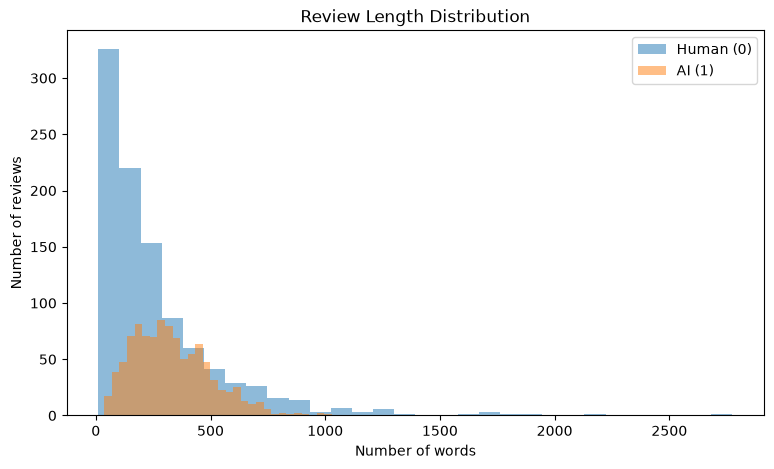

In [89]:
human = df[df["source"] == 0]
ai = df[df["source"] == 1]

plt.figure(figsize=(9, 5))

plt.hist(human["word_count"], bins=30, alpha=0.5, label="Human (0)")
plt.hist(ai["word_count"], bins=30, alpha=0.5, label="AI (1)")

plt.xlabel("Number of words")
plt.ylabel("Number of reviews")
plt.title("Review Length Distribution")

plt.legend()
plt.show()

Very short and ver long reviews

In [90]:
short_reviews = df[df["word_count"] < 20]
short_reviews[["source", "word_count", "review_text"]].head(10)

,source,word_count,review_text
142,0,19,Location is perfect
274,0,14,Great location!
291,0,11,Great place ✌️
323,0,18,Everything! Nothing!
356,0,16,Worst place ever
381,0,18,Great again!!! Thanks!!! ---
641,0,14,Nice and clean
783,0,17,Location and feel.
893,0,14,Great location.
948,0,17,cockroach in room


In [91]:
long_reviews = df[df["word_count"] > 1500]
long_reviews[["source", "word_count", "review_text"]].head(10)

,source,word_count,review_text
156,0,1922,The only good thing there is the receptionists...
189,0,1691,Great location close to the subway. I was very...
319,0,2176,Hotel location is very good.\nHotel rooms are ...
327,0,1810,It was very OK the fact that I could communica...
589,0,1678,Food was excellent We were provided room on th...
779,0,2775,I was very happy with the property!! Especiall...
908,0,1683,Free Wifi and there was a restaurant and cafe ...
916,0,1620,"Location to reach monuments, museums, building..."


Length by source and sentiment

In [92]:
length_by_sentiment = df.groupby(
    ["source", "Sentiment"]
)["word_count"].mean()

length_by_sentiment

source  Sentiment
0       NEG          331.806
        POS          191.352
1       NEG          354.482
        POS          307.516
Name: word_count, dtype: float64

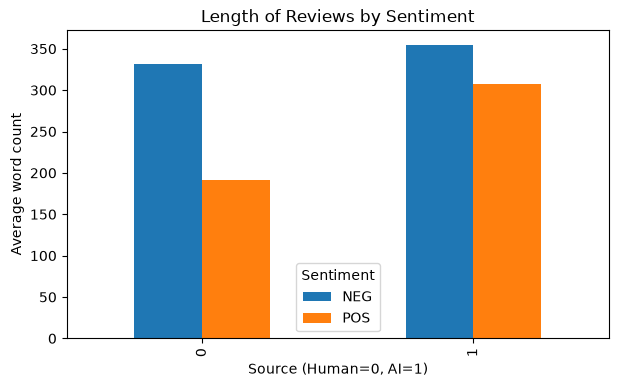

In [93]:
length_by_sentiment = (
    df.groupby(["source", "Sentiment"])["word_count"]
      .mean()
      .unstack()
      .loc[[0,1], ["NEG", "POS"]]
)


length_by_sentiment.plot(kind="bar", figsize=(7,4))

plt.xlabel("Source (Human=0, AI=1)")
plt.ylabel("Average word count")
plt.title("Length of Reviews by Sentiment")


plt.show()

#### Vocabulary analysis

In [94]:
def tokenize(text):
    text = text.lower()
    words = re.findall(r"\b[a-z]+\b", text)
    return words

df["tokens"] = df["review_text"].apply(tokenize)

df[["review_text", "tokens"]].head(10)

,review_text,tokens
0,Staff. Serkan türk was a great help during our...,"[staff, serkan, was, a, great, help, during, o..."
1,Nicely furnished room and nicely decorated lob...,"[nicely, furnished, room, and, nicely, decorat..."
2,"Very central, near 2 metro stations. Room was ...","[very, central, near, metro, stations, room, w..."
3,Lovely interior.. great location.. friendly st...,"[lovely, interior, great, location, friendly, ..."
4,"Thanks to Mr.Serkan, our problems were solved","[thanks, to, mr, serkan, our, problems, were, ..."
5,Location Air-con don't work. Temperature in th...,"[location, air, con, don, t, work, temperature..."
6,Staff were friendly. The A/C was making ALOT o...,"[staff, were, friendly, the, a, c, was, making..."
7,"Nice Furnitures and setups. upon checkout, the...","[nice, furnitures, and, setups, upon, checkout..."
8,property was fine. But if you’re traveling in ...,"[property, was, fine, but, if, you, re, travel..."
9,The sound of the aircondition was terrible,"[the, sound, of, the, aircondition, was, terri..."


In [95]:
# List tokens per review
human_tokens = df[df["source"] == 0]["tokens"]
ai_tokens = df[df["source"]==1]["tokens"]

# List all words in human and AI reviews
human_words = [word for review in human_tokens for word in review]
ai_words = [word for review in ai_tokens for word in review]

print("Human")
print("Total words: ", len(human_words))
print("Unique words: ", len(set(human_words)))

print("AI")
print("Total words: ", len(ai_words))
print("Unique words: ", len(set(ai_words)))

Human
Total words:  48530
Unique words:  4209
AI
Total words:  56231
Unique words:  3033


In [96]:
# Most frequent words

human_freq = Counter(human_words)
ai_freq = Counter(ai_words)

print("Human:", human_freq.most_common(15))
print("AI:", ai_freq.most_common(15))

Human: [('the', 3210), ('and', 1662), ('was', 1344), ('to', 1231), ('a', 1082), ('in', 801), ('room', 743), ('i', 725), ('is', 672), ('of', 620), ('very', 572), ('it', 565), ('for', 541), ('not', 540), ('location', 525)]
AI: [('the', 5330), ('and', 2525), ('was', 2176), ('a', 1340), ('to', 1333), ('of', 1029), ('in', 885), ('hotel', 858), ('were', 765), ('location', 726), ('staff', 707), ('is', 656), ('not', 601), ('room', 597), ('rooms', 592)]


Text(0.5, 1.0, 'Most frequent words in Human Reviews')

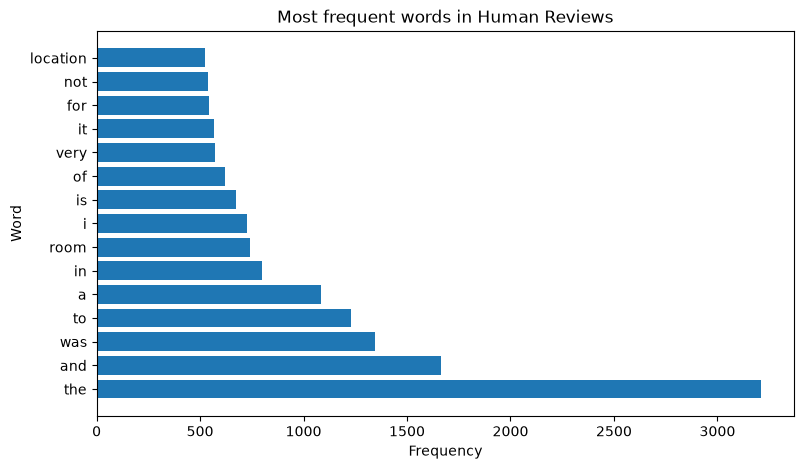

In [97]:
top_human = human_freq.most_common(15)

# words and their counts
words = [item[0] for item in top_human]
counts = [item[1] for item in top_human]
plt.figure(figsize=(9, 5))

plt.barh(words, counts)

plt.xlabel("Frequency")
plt.ylabel("Word")
plt.title("Most frequent words in Human Reviews")

Keeping the stopwords to analyze the language as it appears.

Text(0.5, 1.0, 'Most frequent words in AI Reviews')

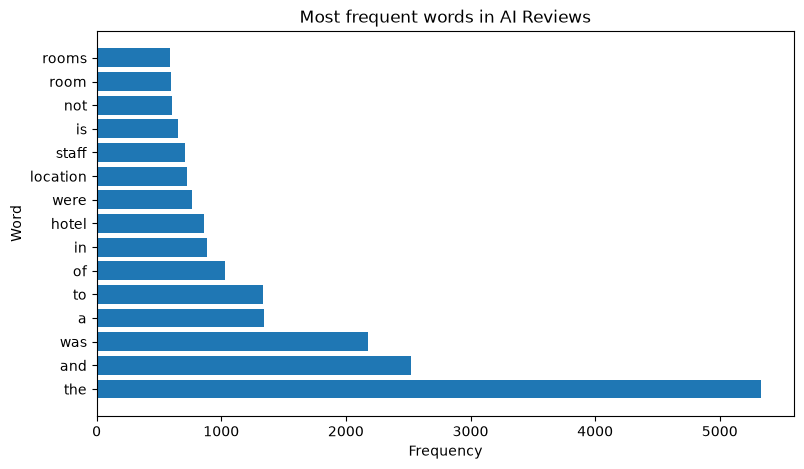

In [98]:
top_ai = ai_freq.most_common(15)

# words and their counts
words = [item[0] for item in top_ai]
counts = [item[1] for item in top_ai]
plt.figure(figsize=(9, 5))

plt.barh(words, counts)

plt.xlabel("Frequency")
plt.ylabel("Word")
plt.title("Most frequent words in AI Reviews")

In [99]:
all_words = set(human_words + ai_words) # all different words in all dataset

human_total = len(human_words)
ai_total = len(ai_words)

res = []

for w in all_words:
    human_count = human_freq[w]
    ai_count = ai_freq[w]

    human_rate = human_count / human_total
    ai_rate = ai_count / ai_total

    res.append([w,human_count, ai_count, human_rate, ai_rate])

res[-6:] # last 6

[['semi', 2, 0, 4.1211621677313004e-05, 0.0],
 ['august', 2, 0, 4.1211621677313004e-05, 0.0],
 ['horrendous', 1, 1, 2.0605810838656502e-05, 1.7783784745069446e-05],
 ['code', 9, 0, 0.0001854522975479085, 0.0],
 ['contortions', 1, 0, 2.0605810838656502e-05, 0.0],
 ['argued', 2, 0, 4.1211621677313004e-05, 0.0]]

In [100]:
word_comparison = pd.DataFrame(
    res,
    columns=["word", "human_count", "ai_count", "human_rate", "ai_rate"]
)
word_comparison.head()

,word,human_count,ai_count,human_rate,ai_rate
0,mix,0,3,0.000000,0.000053
1,mouth,0,1,0.000000,0.000018
2,thoughtfully,0,2,0.000000,0.000036
3,carryon,1,0,0.000021,0.000000
4,inside,28,8,0.000577,0.000142


In [101]:
word_comparison["rate_difference"] = (
    word_comparison["ai_rate"] - word_comparison["human_rate"]
)
# words appearing at least 20 times in total
word_comparison = word_comparison[
    (word_comparison["human_count"] +
     word_comparison["ai_count"]) >= 20
]

word_comparison.nlargest(15, "rate_difference")

,word,human_count,ai_count,human_rate,ai_rate,rate_difference
4069,the,3210,5330,0.066145,0.094788,0.028643
5145,was,1344,2176,0.027694,0.038698,0.011003
3199,and,1662,2525,0.034247,0.044904,0.010657
613,were,346,765,0.007130,0.013605,0.006475
3632,rooms,199,592,0.004101,0.010528,0.006427
597,hotel,461,858,0.009499,0.015258,0.005759
3915,of,620,1029,0.012776,0.018300,0.005524
1996,service,83,367,0.001710,0.006527,0.004816
3010,staff,435,707,0.008964,0.012573,0.003610
3350,with,338,589,0.006965,0.010475,0.003510


In [102]:
word_comparison.nsmallest(15, "rate_difference")

,word,human_count,ai_count,human_rate,ai_rate,rate_difference
790,i,725,306,0.014939,0.005442,-0.009497
43,we,432,88,0.008902,0.001565,-0.007337
2457,very,572,397,0.011787,0.007060,-0.004726
3294,good,354,145,0.007294,0.002579,-0.004716
4339,room,743,597,0.015310,0.010617,-0.004693
180,no,275,60,0.005667,0.001067,-0.004600
2865,for,541,378,0.011148,0.006722,-0.004425
820,that,328,135,0.006759,0.002401,-0.004358
1257,you,260,63,0.005358,0.001120,-0.004237
3500,they,273,84,0.005625,0.001494,-0.004132


By city

In [103]:
city_counts = df["City Name"].value_counts()
city_counts

City Name
Ankara        200
Beijing       200
Berlin        200
Bucharest     200
Madrid        200
New Delhi     200
Paris         200
Rome          200
Seoul         200
Washington    200
Name: count, dtype: int64

By hotel

In [104]:
hotel_counts = df["Hotel Name"].value_counts()
hotel_counts

Hotel Name
Hotel Ickale                         20
Hotel Cinnah                         20
New Park Hotel                       20
The Green Park Ankara                20
Grand Mercure Ankara                 20
                                     ..
Glover Park Hotel Georgetown         20
Hamilton Hotel - Washington DC       20
Riggs Washington DC                  20
Hilton Washington DC Capitol Hill    20
Beacon Hotel & Corporate Quarters    20
Name: count, Length: 100, dtype: int64

In [105]:
hotel_source = pd.crosstab(
    df["Hotel Name"],
    df["source"]
)

hotel_source

source,0,1
Hotel Name,,
AMANO East Side,10,10
AT Central Apartments,10,10
Adveniat Paris,10,10
Alpi Hotel,10,10
Andaz Delhi Aerocity- Concept by Hyatt,10,10
...,...,...
Upstairs Boutique,10,10
Vitan ApartHotel,10,10
citizenM Paris Champs-Élysées,10,10


By score distribution

In [106]:
df.groupby("source")["Review_Score"].describe()

,count,mean,std,min,25%,50%,75%,max
source,,,,,,,,
0,1000.0,6.554,2.892309,2.0,4.0,7.0,9.0,10.0
1,1000.0,5.706,2.766083,2.0,3.0,6.0,8.0,10.0


Humans also better scores.

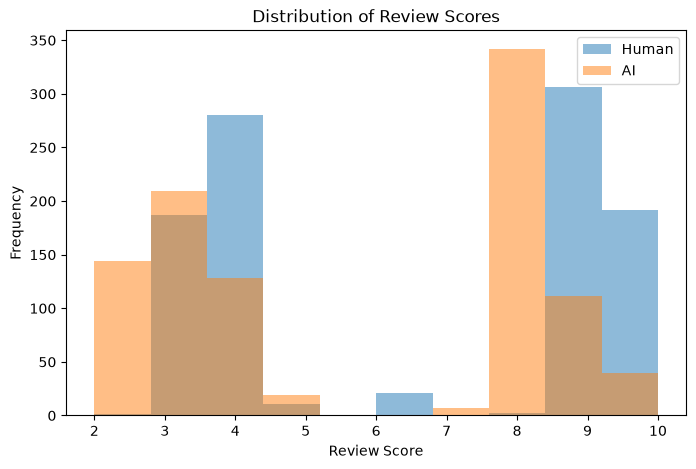

In [107]:
human_scores = human["Review_Score"]
ai_scores = ai["Review_Score"]

plt.figure(figsize=(8,5))

plt.hist(human_scores, bins=10, alpha=0.5, label="Human")
plt.hist(ai_scores, bins=10, alpha=0.5, label="AI")

plt.xlabel("Review Score")
plt.ylabel("Frequency")
plt.title("Distribution of Review Scores")
plt.legend()
plt.show()